## Model: bleeding on probing during supportive periodontal therapy

$$
Y_{ij} = \beta_0 + f_{g(i)}(\text{Follow-up time}_{ij}) + \boldsymbol\beta^\top X_{ij} + \mathbf{b}_i^\top \mathbf{w}_{ij} + \epsilon_{ij}, \qquad \mathbf{b}_i \sim N(\mathbf{0}, D),\quad \epsilon_{ij} \overset{\text{iid}}{\sim} N(0, \sigma^2)
$$

**Outcome.** $Y_{ij} = \operatorname{logit}\big((\text{bleeding percentage} + 0.5)/101\big)$ at supportive periodontal therapy (SPT) visit $j$ of patient $i$, where the percentage is bleeding sites / (teeth $\times$ 4) $\times$ 100. The raw percentage is a bounded proportion of sites, right-skewed with spread growing in its level, so the logit scale respects the bounds and stabilizes the variance. The offset (0.5 and 101) keeps the 0% (2.9% of visits) and 100% visits finite. Coefficients are differences in log-odds, and $e^{\beta}$ is the odds ratio per unit.

**Rows.** Visits 2 onward, since the first visit has no preceding visit. Rows with a missing outcome, smooth input or covariate are dropped, with no imputation. No visit is dropped for a long gap, and the 7 top-coded visits at age 90 (4 patients) are kept.

**Smooth term.** The only nonlinear term is follow-up time (cumulative years since the first visit, penalized spline), with a separate curve $f_g$ for each of the 3 baseline diagnosis classes $\times$ 2 sexes = 6 groups. Each curve is fitted on its own group's visits (`curve_type = "specific"`); `"difference"` would fit a reference curve plus difference curves.

**Fixed effects.** All linear:
- age at visit, calendar year, teeth at the visit
- log time since the preceding visit (natural log of days, per 1-unit increase; the raw gap is right-skewed, up to 4477 days)
- ever-smoker (former or current) vs. never-smoker
- sex, baseline disease class (reference class 1) and their interaction

Continuous terms are standardized (mean 0, SD 1 on the analysis sample), so coefficients are per SD and $D$ is well conditioned.

**Random effects.** A patient intercept plus random slopes on age at visit and log time since the preceding visit, with unstructured $D$. Within a patient, age, calendar year and follow-up time are almost perfectly correlated, so one slope among them is enough and more would make $D$ singular. A slope on a variable constant within a patient (such as baseline class) is not identifiable and only rescales the intercept, so those terms have fixed slopes only.

**Residuals.** iid across a patient's visits. Within-patient correlation comes from the random effects, and a compound-symmetry residual would duplicate the random intercept.

**Data.** `spt_data/curated_spt_bleeding.csv`, curated from the files in `spt_data/`.


In [1]:
## settings: population, covariates, random slopes, filters
import os
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import torchpalmm as tp
from scipy import stats

data_csv = "spt_data/curated_spt_bleeding.csv"
population = "all"                                            # "all": 883 patients; "subsample445": healthy at baseline and >= 5 years in SPT (the Table 2 population; baseline diagnosis recorded)
drop_age90 = False                                            # age_at_spt = 90 means 90 or older (de-identification); True drops those visits (7 visits, 4 patients), False keeps them with age top-coded at 90
max_interval_days = None                                      # a visit more than 2 years after the previous one is a lapse from routine recall: it and all later visits of that patient are dropped (None keeps all; the maximum is 4477 days)
corr_structure = "iid"                                       # residual correlation across a patient's visits: 'ar1', 'iid' or 'cs'
outcome = "bleeding_pct"
outcome_transform = "logit"                                   # "logit": the model outcome is logit((bleeding % + 0.5) / 101); "log1p": log(bleeding % + 1); "none": the raw percentage
assert outcome_transform in ("logit", "log1p", "none")
logit_off = (0.5, 101)                                        # p = (bleeding % + 0.5) / 101 keeps the 0% and 100% visits inside (0, 1)
eff_label = {"logit": "Change in logit(bleeding)", "log1p": "Change in log(bleeding + 1)", "none": "Change in bleeding on probing (percentage points)"}[outcome_transform]
re_unit = {"logit": "logit units", "log1p": "log units", "none": "percentage points"}[outcome_transform]
## smooths (column, label, grid): inputs are rounded to the grid so each smooth has about 100-300 distinct values (torchpalmm uses about one basis column per distinct value)
smooth_spec = [
    ("cum_followup_years", "Follow-up time (years)", 0.1),
]
followup_by_strata = True                                     # True: separate follow-up curves for every baseline diagnosis class x sex group; False: one curve for everyone. Class, sex and class x sex are fixed effects
curve_type = "specific"                                      # "specific": every class x sex group has its own full curve, fitted on that group's visits only; "difference": reference curve (largest group, all visits) + a difference curve per other group
assert curve_type in ("specific", "difference")
strata_var = "sex"                                           # second grouping variable (a binary column of the analysis sample); its binary_cols level is the "1"
smooth_cols = [s[0] for s in smooth_spec]; smooth_labels = [s[1] for s in smooth_spec]

## continuous linear terms: (column, label, size of the "natural unit" for the effect table, unit name)
cont_spec = [
    ("age_at_spt",            "Age at visit",                   1,   "per year"),
    ("calendar_year",         "Calendar year of visit",         1,   "per year"),
    ("n_teeth_spt",      "Teeth at visit",              1,   "per tooth"),
    ("log_days_since_prev_visit", "log(time since preceding visit, days)", 1, "per unit"),
]
random_slope_cols = ["age_at_spt"]   # random slopes (only variables that vary within a patient); [] = random intercept only. Within a patient age at visit, calendar year and follow-up time move together (correlation about 1), so a slope on any one of them is the same random slope: use one of them, not several
scale_continuous = True                                       # standardize the continuous linear terms (mean 0, SD 1)
x_cols_cat = {"baseline_diagnosis": ("1", ["2", "3"])}    # (reference, dummies)

binary_cols = {"sex": "female", "ever_smoker": "ever"}       # 1 = this level; ever_smoker merges former smoker and smoker (reference: never-smoker)
q_thr = 0.05                                                  # BH q threshold for the fixed effects
cont_cols = [c[0] for c in cont_spec]
random_only_labels = {"calendar_year": "Calendar year of visit"}   # random slopes on variables that are not fixed effects: label (standardized like the continuous terms)
assert set(random_slope_cols) <= set(cont_cols) | set(random_only_labels)

In [2]:
## analysis sample: complete cases for the outcome, the smooth input, the continuous terms and the covariates
df = pd.read_csv(data_csv)
df = df[df["spt_id"] >= 2]                                    # first visit excluded
if population == "subsample445":
    df = df[df["subsample_5years"] == 1]
n0 = len(df)
df["baseline_diagnosis"] = df["baseline_diagnosis"].astype(str)
if drop_age90:
    df = df[df["age_at_spt"] < 90]
n_i = len(df)
if max_interval_days is not None:                             # a lapse from recall: the first visit more than max_interval_days after the preceding one, and every later visit of that patient, are dropped
    df = df.sort_values(["pat_id", "spt_id"])
    lapsed = df.groupby("pat_id")["days_since_prev_visit"].transform(lambda s: (s > max_interval_days).cummax()).astype(bool)
    print(f"patients with a lapse > {max_interval_days} days: {df.loc[lapsed, 'pat_id'].nunique()}; patients left with no visit: {df['pat_id'].nunique() - df.loc[~lapsed, 'pat_id'].nunique()}")
    df = df[~lapsed]
print(f"visits 2 onward: {n0}; dropped for age 90 (90 or older): {n0 - n_i}; dropped at or after a lapse > {max_interval_days} days: {n_i - len(df)}")
assert (df["days_since_prev_visit"] > 0).all()
df["log_days_since_prev_visit"] = np.log(df["days_since_prev_visit"])   # time since the preceding visit is right-skewed (max 4477 days): natural log, coefficient per 1-unit increase in log(days) in the natural-unit table
df["ever_smoker"] = np.where(df["smoking_status"].isna(), None, np.where(df["smoking_status"] == "non-smoker", "never", "ever"))   # former smoker + smoker merged; missing stays missing
need_cols = [outcome] + smooth_cols + cont_cols + list(x_cols_cat) + list(binary_cols)
n1 = len(df)
df = df.dropna(subset=need_cols).sort_values(["pat_id", "spt_id"]).reset_index(drop=True)
print(f"dropped for a missing outcome, smooth input or covariate: {n1 - len(df)}")
for c, _, g in smooth_spec:
    df[c] = (df[c] / g).round() * g                              # round to the grid
## AR(1) in torchpalmm uses row order within patient (gaps count as adjacent): rows must be in visit order
assert (df.groupby("pat_id")["spt_id"].diff().dropna() > 0).all()
gap = df.groupby("pat_id")["spt_id"].diff().dropna()
print(f"consecutive analysed visits more than 1 visit apart: {(gap > 1).mean():.1%} of {len(gap)} pairs")
n_vis = df.groupby("pat_id").size()
print(f"{len(df)} visits, {df['pat_id'].nunique()} patients; visits per patient (median, range): {int(n_vis.median())}, {n_vis.min()}-{n_vis.max()}")
## a random slope needs variation within patients
within_sd = df.groupby("pat_id")[list(dict.fromkeys(cont_cols + random_slope_cols))].std().mean()
print("mean within-patient SD of each continuous term and random slope variable:", within_sd.round(2).to_dict())
assert all(within_sd[c] > 0 for c in random_slope_cols), "a random slope on a within-patient constant variable is not identifiable"

visits 2 onward: 10959; dropped for age 90 (90 or older): 0; dropped at or after a lapse > None days: 0
dropped for a missing outcome, smooth input or covariate: 13
consecutive analysed visits more than 1 visit apart: 0.1% of 10063 pairs
10946 visits, 883 patients; visits per patient (median, range): 8, 1-69
mean within-patient SD of each continuous term and random slope variable: {'age_at_spt': 2.65, 'calendar_year': 2.65, 'n_teeth_spt': 0.26, 'log_days_since_prev_visit': 0.42}


In [3]:
len(df.pat_id.unique())

883

In [4]:
## design: smooth input, fixed-effect matrix X (standardized continuous + dummies), random-effect matrix Z (intercept + random slopes), outcome
spline_inputs = df[smooth_cols].to_numpy(float)
smooth_mask = np.ones_like(spline_inputs)
spline_names = list(smooth_labels)
grp_id = {}                                                   # grp_id[group] = spline id of the group's own curve (specific) or of its difference curve (difference; the reference group has the reference curve's id)
if followup_by_strata:
    assert len(smooth_cols) == 1, "the strata curves replace the single follow-up smooth"
    k_f = 0
    grp = "class " + df["baseline_diagnosis"].astype(str) + ", " + df[strata_var].astype(str)
    n_grp = grp.value_counts(); groups = sorted(n_grp.index)
    if curve_type == "specific":                              # one full curve per group, each active only on that group's visits (the masks do not overlap)
        spline_inputs = np.column_stack([spline_inputs[:, k_f]] * len(groups))
        smooth_mask = np.column_stack([(grp == g).to_numpy().astype(float) for g in groups])
        spline_names = [f"{smooth_labels[k_f]}, {g}" for g in groups]
        grp_id = {g: i for i, g in enumerate(groups)}
        print("visits per group:", n_grp.sort_index().to_dict())
    else:                                                     # reference curve (largest group, all visits) + a difference curve per other group on that group's visits
        ref_g = n_grp.index[0]; grp_id[ref_g] = 0
        spline_names[k_f] = f"{smooth_labels[k_f]}, {ref_g} (reference)"
        for g in sorted(n_grp.index[1:]):
            grp_id[g] = len(spline_names)
            spline_inputs = np.column_stack([spline_inputs, spline_inputs[:, k_f]])
            smooth_mask = np.column_stack([smooth_mask, (grp == g).to_numpy().astype(float)])
            spline_names.append(f"{smooth_labels[k_f]}: {g} vs. {ref_g}")
        print("visits per group:", n_grp.sort_index().to_dict(), "| reference group:", ref_g)
mu = df[cont_cols].mean(); sd = df[cont_cols].std()
if scale_continuous:
    cont_z = (df[cont_cols] - mu) / sd
else:
    cont_z, sd = df[cont_cols].copy(), pd.Series(1.0, index=cont_cols)
x_parts, x_names = [], []
for c, lab, *_ in cont_spec:
    x_parts.append(cont_z[c].to_numpy()); x_names.append(lab + (" (per SD)" if scale_continuous else ""))
for c, (ref, levels) in x_cols_cat.items():
    for lv in levels:
        x_parts.append((df[c] == lv).astype(float).to_numpy()); x_names.append(f"{c}: {lv} vs. {ref}")
for c, lv in binary_cols.items():
    x_parts.append((df[c] == lv).astype(float).to_numpy()); x_names.append(f"{c}: {lv}")
if followup_by_strata:                                        # class x group product terms: with the main effects every class x group level lies in the fixed part (no level columns)
    for lv in x_cols_cat["baseline_diagnosis"][1]:
        x_parts.append(((df["baseline_diagnosis"] == lv) & (df[strata_var] == binary_cols[strata_var])).astype(float).to_numpy())
        x_names.append(f"class {lv} x {strata_var}: {binary_cols[strata_var]}")
X = np.column_stack(x_parts)
re_label = {**{c[0]: c[1] for c in cont_spec}, **random_only_labels}
re_z = pd.DataFrame({c: cont_z[c] if c in cont_cols else ((df[c] - df[c].mean()) / df[c].std() if scale_continuous else df[c]) for c in random_slope_cols})   # standardized slope covariates
re_names = ["intercept"] + [re_label[c] + " (slope)" for c in random_slope_cols]
Z = np.column_stack([np.ones(len(df))] + [re_z[c].to_numpy() for c in random_slope_cols])
y_raw = df[outcome].to_numpy(float)
p_adj = (y_raw + logit_off[0]) / logit_off[1]
y = torch.as_tensor({"logit": np.log(p_adj / (1 - p_adj)), "log1p": np.log1p(y_raw), "none": y_raw}[outcome_transform]).view(-1, 1)   # model outcome
obs_id = pd.factorize(df["pat_id"])[0]
act = lambda j: smooth_mask[:, j] > 0

visits per group: {'class 1, female': 604, 'class 1, male': 409, 'class 2, female': 2842, 'class 2, male': 2345, 'class 3, female': 2531, 'class 3, male': 2215}


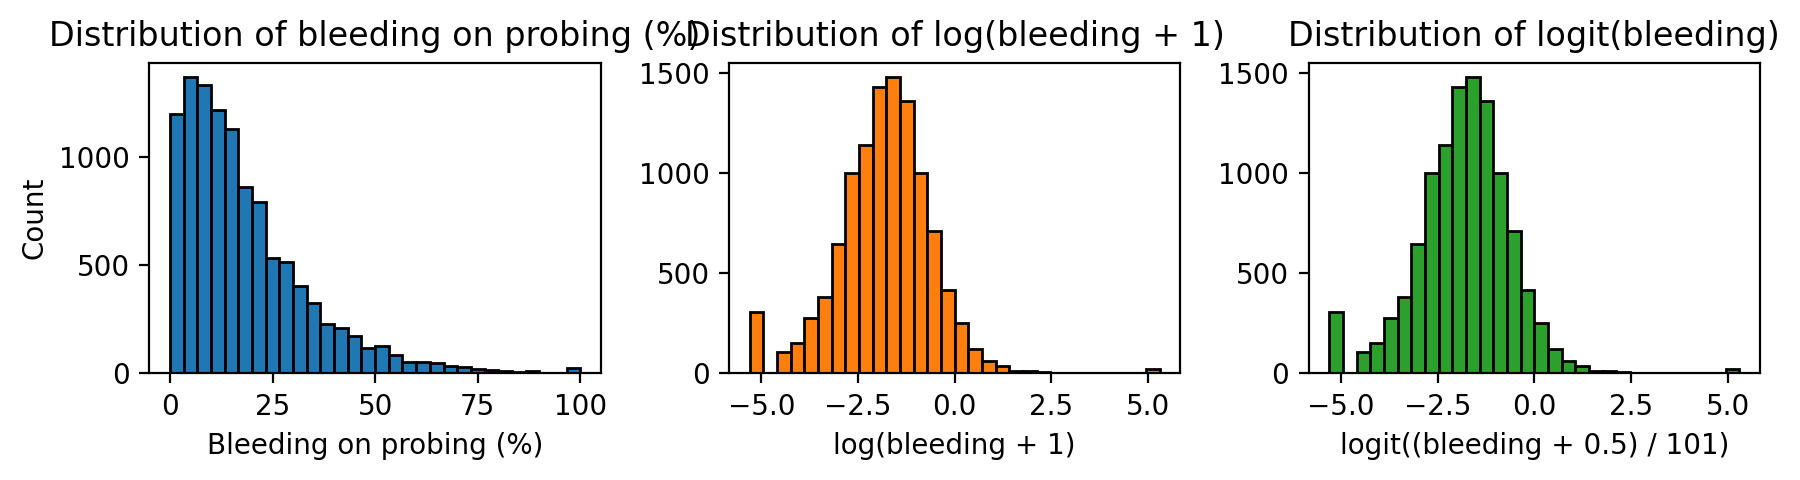

In [5]:
## distribution of the raw outcome, log(y + 1) (the model outcome) and logit(y)
plt.figure(figsize=(9, 2.5), dpi=200)
plt.subplot(1, 3, 1)
plt.hist(y_raw, bins=30, color="C0", edgecolor="black")
plt.title("Distribution of bleeding on probing (%)")
plt.xlabel("Bleeding on probing (%)")
plt.ylabel("Count")
plt.subplot(1, 3, 2)
plt.hist(y.numpy().flatten(), bins=30, color="C1", edgecolor="black")
plt.title("Distribution of log(bleeding + 1)")
plt.xlabel("log(bleeding + 1)")
plt.subplot(1, 3, 3)
p_adj = (y_raw + 0.5) / 101                                   # shrink 0% and 100% inside (0, 1) so the logit is finite
plt.hist(np.log(p_adj / (1 - p_adj)), bins=30, color="C2", edgecolor="black")
plt.title("Distribution of logit(bleeding)")
plt.xlabel("logit((bleeding + 0.5) / 101)")
plt.tight_layout()


In [6]:
## singularity check before fitting: rank and condition number of [intercept, X, centred linear part of the smooth], and near-collinear pairs
lin = np.column_stack([(spline_inputs[:, j] - spline_inputs[smooth_mask[:, j] > 0, j].mean()) * smooth_mask[:, j] for j in range(spline_inputs.shape[1])])   # centred on the active rows
A = np.column_stack([np.ones(len(X)), X, lin]); names = ["Intercept"] + x_names + [f"s({n}) linear" for n in spline_names]
U, sv, Vt = np.linalg.svd(A / np.maximum(np.linalg.norm(A, axis=0), 1e-12), full_matrices=False)
rank = int((sv > sv[0] * 1e-8).sum())
print(f"rows {A.shape[0]}, columns {A.shape[1]}, rank {rank} -> {'OK' if rank == A.shape[1] else 'SINGULAR'}; condition number {sv[0] / sv[-1]:.3g}")
for k in range(A.shape[1] - 1, rank - 1, -1):
    v = Vt[k]; print(f"dependency {A.shape[1] - k}: ", ", ".join(f"{names[i]} ({v[i]:+.2f})" for i in np.argsort(-np.abs(v)) if abs(v[i]) > 0.1))
C = pd.DataFrame(A[:, 1:], columns=names[1:]).corr().abs().where(lambda d: np.triu(np.ones(d.shape, bool), 1))
hi = C.stack().loc[lambda s: s > 0.8].sort_values(ascending=False)
print("pairs with |corr| > 0.8:", "none" if hi.empty else "\n" + hi.round(3).to_string())
W = pd.DataFrame(A[:, 1:], columns=names[1:]); W = W.loc[:, W.std() > 0]
print(pd.Series(np.diag(np.linalg.inv(W.corr().to_numpy())), index=W.columns, name="VIF").round(2).to_string())

rows 10946, columns 17, rank 17 -> OK; condition number 18.7
pairs with |corr| > 0.8: 
baseline_diagnosis: 2 vs. 1  baseline_diagnosis: 3 vs. 1    0.83
Age at visit (per SD)                                 1.64
Calendar year of visit (per SD)                       1.18
Teeth at visit (per SD)                               1.42
log(time since preceding visit, days) (per SD)        1.15
baseline_diagnosis: 2 vs. 1                           8.00
baseline_diagnosis: 3 vs. 1                           8.36
sex: female                                          11.20
ever_smoker: ever                                     1.15
class 2 x sex: female                                10.29
class 3 x sex: female                                 9.70
s(Follow-up time (years), class 1, female) linear     1.02
s(Follow-up time (years), class 1, male) linear       1.01
s(Follow-up time (years), class 2, female) linear     1.05
s(Follow-up time (years), class 2, male) linear       1.05
s(Follow-up time (year

In [7]:
## fit: REML, LBFGS
ss = tp.SmoothingSplineMixed(y=y, X=X, Z=Z, spline_inputs=spline_inputs, obs_id=obs_id, smooth_mask=smooth_mask,
                             corr_structure=corr_structure, rand_D_type="unstructured")
print("level columns added:", ss.level_names, "| total basis:", sum(nb.shape[-1] for nb in ss.NB_list))
torch.manual_seed(0)
ss.fit(optimizer=torch.optim.LBFGS, lr=5, max_iter=10000, fit_type="reml", convg_check="all",
       verbose=True)

level columns added: [] | total basis: 1245


/Users/rui/lmm_pytorch/lmm/lib/python3.13/site-packages/torchpalmm/linear_mixed_model.py:644: UserWarning: LinearMixedModelSmoothing: 128 of 883 subjects (14%) have rank(Z_i) < q = 2 (e.g. fewer rows than random effects); their random effects are not identified from their own rows and trade off against sigma^2.
  warnings.warn(f"{type(self).__name__}: {k} of {self.n_groups} subjects ({k / self.n_groups:.0%}) have "


LinearMixedModelSmoothing: REML fit
  data      10946 obs in 883 groups (max 69 per group)
  fixed     p = 17
  random    q = 2, D unstructured
  residual  iid
  smooths   S = 6, K = 178, 155, 223, 241, 230, 218
  start     OLS beta = [-0.07635, 0.1168, -0.1318, 0.1625, 0.6825, 0.642, ...]

  LBFGS: lr=5, max_iter=10000 (1000 outer steps of up to 10 iterations), tol=1e-06 on all
  outer             loss    rel_loss   rel_param   grad_norm
      0    345303.365792           -    9.42e+11    2.12e+01
     10    345186.321365    0.00e+00    0.00e+00    8.92e-06
  converged at outer step 10 (67 L-BFGS iterations, 139 evaluations): loss = 345186.321365 (20.47 s)


/Users/rui/lmm_pytorch/lmm/lib/python3.13/site-packages/torchpalmm/linear_mixed_model.py:669: UserWarning: LinearMixedModelSmoothing: variance component(s) on the boundary (~0): tau2 s(spline4). converged does not mean an interior optimum; consider dropping them.
  warnings.warn(f"{name}: variance component(s) on the boundary (~0): {', '.join(self.boundary)}. "


In [8]:
## model specification (as fitted), coefficients, variance components and the smooth test
spec = pd.Series({
    "outcome": ({"logit": f"logit({outcome} / 100)", "log1p": f"log({outcome} + 1)", "none": f"{outcome} (%)"}[outcome_transform]) + ", SPT visits 2 onward",
    "smooth": ", ".join(spline_names),
    "fixed effects": ", ".join(x_names),
    "random effects": ", ".join(re_names),
    "random-effect covariance": ss.rand_D_type,
    "residual correlation": ss.corr_structure,
    "population": population,
    "rows / patients": f"{len(df)} / {df['pat_id'].nunique()}",
    "total basis": sum(b.shape[-1] for b in ss.NB_list),
    "estimation": "REML, LBFGS",
}, name="model specification")
print(spec.to_string())

out = ss.summary(names=x_names, spline_names=spline_names, re_names=re_names)
tests = out["splines"].set_index("spline_id")
fdf = ss.smooth_confint()

def bh_adjust(p):
    '''Benjamini-Hochberg adjusted p-values (q); NaN stays NaN.'''
    p = np.asarray(p, float); order, m = np.argsort(np.where(np.isnan(p), 2, p)), len(p)
    adj = np.where(np.isnan(p[order]), np.nan, p[order] * m / np.arange(1, m + 1))
    q = np.empty(m); q[order] = np.fmin.accumulate(adj[::-1])[::-1].clip(max=1)
    return q

tests["q_fisher"] = bh_adjust(tests["p_fisher"])                # BH across the smooths (overall Fisher p)
tests["q_nonlinear"] = bh_adjust(tests["p_nonlinear"])        # and for the test of linearity
coef = out["coefficients"].set_index("term")
fx = coef.loc[x_names].copy()                                 # fixed effects (BH across them; the smooths have their own overall tests below)
fx["q_value"] = bh_adjust(fx["p_value"])
print(fx[["estimate", "se", "ci_lower", "ci_upper", "p_value", "q_value"]].round(4).to_string())
print("\nvariance components:"); print(out["variance"].round(4).to_string())
print("\nsmooths:"); print(tests[["term", "edf", "p_linear", "p_nonlinear", "q_nonlinear", "p_fisher", "q_fisher", "null_converged", "edf_conflict"]].round(4).to_string())   # null_converged: null refit of the linearity test; edf_conflict: linearity rejected while EDF ~ 1

## effect of the continuous terms in natural units (estimate per SD / SD x unit size)
nat = pd.DataFrame({"effect": [f"{unit}" for _, _, _, unit in cont_spec],
                    "estimate": [fx.loc[x_names[k], "estimate"] / sd[c] * size for k, (c, _, size, _) in enumerate(cont_spec)],
                    "ci_lower": [fx.loc[x_names[k], "ci_lower"] / sd[c] * size for k, (c, _, size, _) in enumerate(cont_spec)],
                    "ci_upper": [fx.loc[x_names[k], "ci_upper"] / sd[c] * size for k, (c, _, size, _) in enumerate(cont_spec)]},
                  index=[lab for _, lab, _, _ in cont_spec])
print(f"\n{eff_label} in natural units:"); print(nat.round(3).to_string())
if outcome_transform == "logit":                              # odds ratios: exp(estimate)
    print("\nodds ratio, natural units / dummy contrasts:")
    print(pd.concat([pd.DataFrame({k: np.exp(nat[k]) for k in ("estimate", "ci_lower", "ci_upper")}),
                     pd.DataFrame({k: np.exp(fx.loc[x_names[len(cont_cols):], k]) for k in ("estimate", "ci_lower", "ci_upper")})]).round(3).to_string())
if outcome_transform == "log1p":                              # ratio of (bleeding + 1): 100 (exp(estimate) - 1) is the % change
    pct = lambda v: 100 * (np.exp(v) - 1)
    print("\n% change in (bleeding + 1), natural units / dummy contrasts:")
    print(pd.concat([pd.DataFrame({k: pct(nat[k]) for k in ("estimate", "ci_lower", "ci_upper")}),
                     pd.DataFrame({k: pct(fx.loc[x_names[len(cont_cols):], k]) for k in ("estimate", "ci_lower", "ci_upper")})]).round(1).to_string())

outcome                        logit(bleeding_pct / 100), SPT visits 2 onward
smooth                      Follow-up time (years), class 1, female, Follo...
fixed effects               Age at visit (per SD), Calendar year of visit ...
random effects                                intercept, Age at visit (slope)
random-effect covariance                                         unstructured
residual correlation                                                      iid
population                                                                all
rows / patients                                                   10946 / 883
total basis                                                              1245
estimation                                                        REML, LBFGS


/Users/rui/lmm_pytorch/lmm/lib/python3.13/site-packages/torchpalmm/linear_mixed_model.py:803: UserWarning: LinearMixedModelSmoothing: the Hessian is flat only along boundary component(s) tau2 s(Follow-up time (years), class 2, male) (estimated at ~0); the Satterthwaite df hold them at 0, as in a model without them. This is expected for a variance at 0.
  warnings.warn(f"{type(self).__name__}: the Hessian is flat only along boundary component(s) "


                                                estimate      se  ci_lower  ci_upper  p_value  q_value
term                                                                                                  
Age at visit (per SD)                            -0.0502  0.0415   -0.1317    0.0314   0.2277   0.3795
Calendar year of visit (per SD)                   0.0719  0.0285    0.0159    0.1279   0.0119   0.0298
Teeth at visit (per SD)                          -0.0370  0.0352   -0.1060    0.0320   0.2932   0.4188
log(time since preceding visit, days) (per SD)    0.1496  0.0116    0.1269    0.1723   0.0000   0.0000
baseline_diagnosis: 2 vs. 1                       0.4864  0.1547    0.1827    0.7901   0.0017   0.0057
baseline_diagnosis: 3 vs. 1                       0.6204  0.1629    0.3007    0.9401   0.0001   0.0007
sex: female                                      -0.1199  0.1815   -0.4761    0.2364   0.5092   0.6365
ever_smoker: ever                                -0.1002  0.0657   -0.229

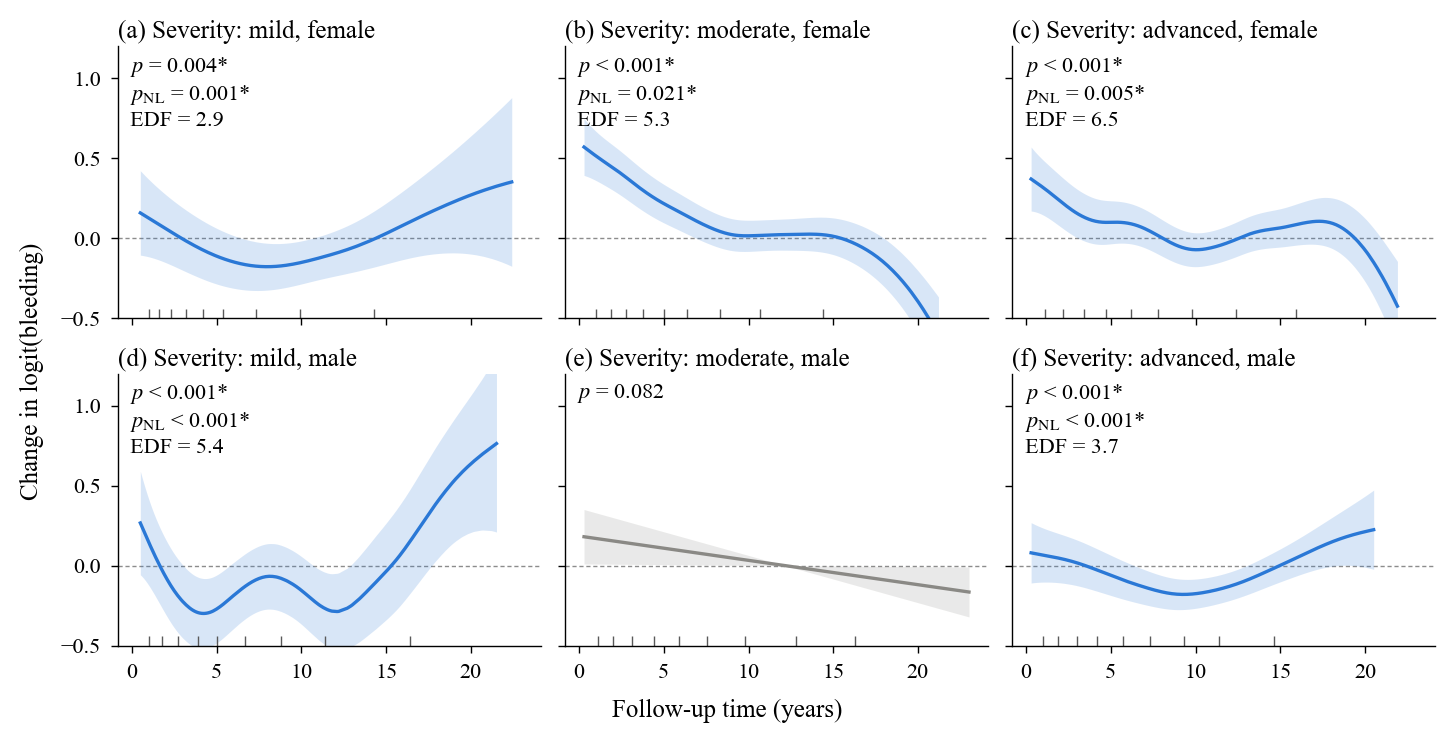

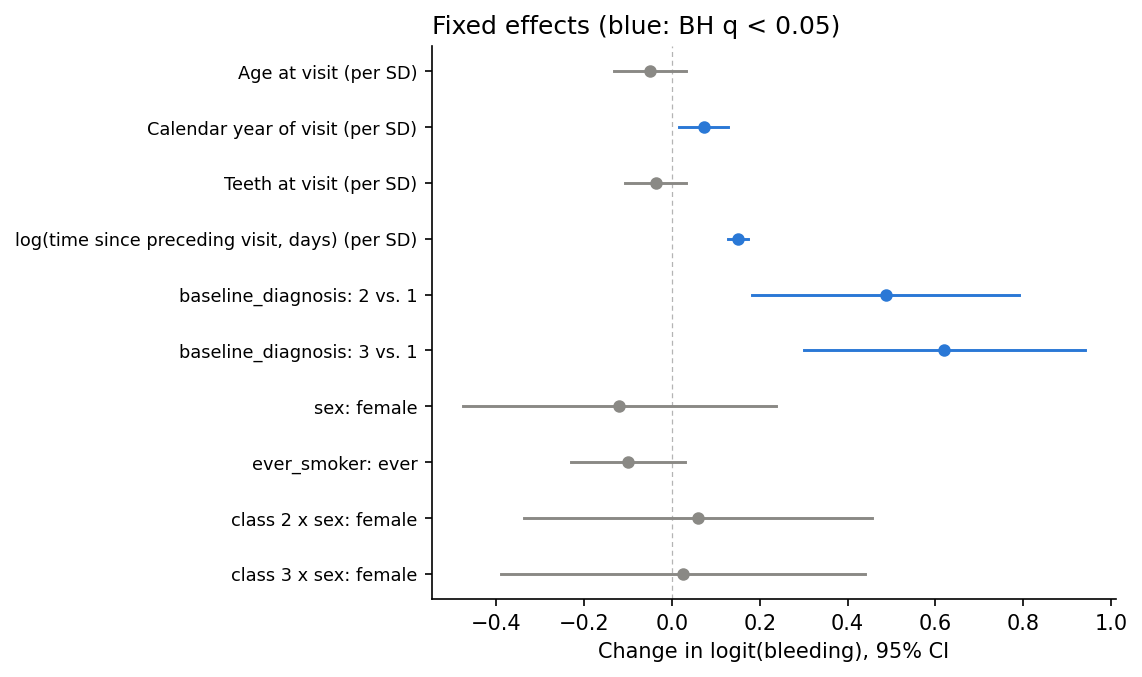

In [9]:
## results figures: smooth curves (centred, pointwise 95% band; difference curves are relative to the reference group) and a forest plot of the fixed effects (continuous terms per SD)
blue, flat, ink = "#2a78d6", "#8a8985", "#0b0b0b"
sev_label = {"1": "mild", "2": "moderate", "3": "advanced"}   # panel titles: baseline diagnosis class 1/2/3
n_sm = len(spline_names)
if followup_by_strata:                                        # grid: columns = baseline class, rows = sex; panel (row, col) shows that group's curve
    classes = sorted(df["baseline_diagnosis"].unique()); strata = sorted(df[strata_var].astype(str).unique())
    n_row, n_col = len(strata), len(classes)
    cell_of = {grp_id[f"class {cl}, {sx}"]: (r_, c_) for r_, sx in enumerate(strata) for c_, cl in enumerate(classes)}
else:
    n_col = min(n_sm, 3); n_row = int(np.ceil(n_sm / n_col))
    cell_of = {sid: (sid // n_col, sid % n_col) for sid in range(n_sm)}
## IEEE-style figure: double-column width (7.16 in), serif text at 9 pt (8 pt ticks and annotations), 0.5 pt axes and outward ticks (kept apart from the inner decile rug),
## blue curve and band when the curve is significant (BH q < q_thr), gray otherwise; shared axes with one x and one y label, panel letters
ieee = {"font.family": "serif", "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"], "mathtext.fontset": "stix",
        "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
        "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
        "xtick.direction": "out", "ytick.direction": "out", "xtick.top": False, "ytick.right": False,
        "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 600}
pfmt_ = lambda v: "n/a" if np.isnan(v) else "< 0.001" if v < 1e-3 else f"= {v:.3f}"
with plt.rc_context(ieee):
    fig, axs = plt.subplots(n_row, n_col, figsize=(7.16, 1.6 * n_row + 0.4), sharex=True, sharey=True, squeeze=False, layout="constrained", dpi=200)
    for sid in sorted(cell_of, key=cell_of.get):
        r_, c_ = cell_of[sid]
        ax, t = axs[r_, c_], tests.loc[sid]
        on = smooth_mask[:, sid] > 0                          # rows where this smooth is active
        d = fdf[fdf["spline_id"] == sid]
        lo, hi = np.percentile(spline_inputs[on, sid], [1, 99])
        d = d[d["spline_var"].between(lo, hi)]                # sparse tails are not drawn
        ax.axhline(0, color="0.55", lw=0.5, ls=(0, (3, 2)), zorder=0)
        col = blue if t["q_fisher"] < q_thr else flat         # BH q across the smooths
        ax.fill_between(d["spline_var"], d["lower"], d["upper"], color=col, alpha=0.18, lw=0, zorder=1)
        ax.plot(d["spline_var"], d["theta_fitted"], color=col, lw=1.2, zorder=2)
        ax.vlines(np.quantile(spline_inputs[on, sid], np.linspace(.1, .9, 9)), 0, 0.035, transform=ax.get_xaxis_transform(), color="0.35", lw=0.5)   # deciles of follow-up in this group
        lines = [f"$p$ {pfmt_(t['p_fisher'])}{'*' if t['q_fisher'] < q_thr else ''}"]
        if t["edf"] > 1.05:                                   # curves that are not straight lines: score test of linearity and EDF
            lines += [f"$p_{{\\mathrm{{NL}}}}$ {pfmt_(t['p_nonlinear'])}{'*' if t['q_nonlinear'] < q_thr else ''}", f"EDF = {t['edf']:.1f}"]
        ax.text(0.03, 0.97, "\n".join(lines), transform=ax.transAxes, ha="left", va="top", fontsize=8, linespacing=1.25)
        lab = spline_names[sid].replace(smooth_labels[0], "").lstrip(",: ") or spline_names[sid]
        for k_, v_ in sev_label.items():                      # baseline diagnosis class -> severity
            lab = lab.replace(f"class {k_}", f"Severity: {v_}")
        ax.set_title(f"({chr(97 + r_ * n_col + c_)}) {lab[:1].upper() + lab[1:]}", loc="left", pad=3)
        ax.spines[["top", "right"]].set_visible(False)
        ax.minorticks_off()
    for k_ in range(len(cell_of), n_row * n_col):
        axs[k_ // n_col, k_ % n_col].axis("off")
    axs[0, 0].set_ylim(-0.5, 1.2)                          # shared y; the space above the curves holds the test annotations
    fig.supxlabel(smooth_labels[0], fontsize=9)
    fig.supylabel(eff_label, fontsize=9)
    plt.show()

fig, ax2 = plt.subplots(figsize=(7.5, 4.4), layout="constrained", dpi=150)
rows = fx.iloc[::-1]
ypos = np.arange(len(rows))
sig = (rows["q_value"] < q_thr).to_numpy()
ax2.axvline(0, color="#b4b4b4", lw=0.6, ls=(0, (4, 3)), zorder=0)
for yy, (_, r), s_ in zip(ypos, rows.iterrows(), sig):
    ax2.plot([r["ci_lower"], r["ci_upper"]], [yy, yy], color=blue if s_ else flat, lw=1.4)
    ax2.plot(r["estimate"], yy, "o", color=blue if s_ else flat, ms=5)
ax2.set_yticks(ypos); ax2.set_yticklabels(rows.index, fontsize=8.5)
ax2.set_xlabel(eff_label + ", 95% CI")
ax2.set_title(f"Fixed effects (blue: BH q < {q_thr})", loc="left")
ax2.spines[["top", "right"]].set_visible(False)
plt.show()

In [10]:
## random-effect covariance D (1/3): variances, correlations, conditioning and flags
D = ss.D.cpu().numpy()
s2 = float(ss.sigma2)                                         # residual variance
q_re = D.shape[0]
sd_re = np.sqrt(np.diag(D))
corr_re = D / np.outer(sd_re, sd_re)
ev = np.linalg.eigvalsh(D)

## slope SDs are per SD of the covariate (standardized): divide by the covariate SD for the natural unit
slope_unit = {"age_at_spt": "year", "calendar_year": "year", "days_since_prev_visit": "day", "log_days_since_prev_visit": "unit of log(days)"}
to_natural = np.r_[1.0, [1.0 / sd[c] for c in random_slope_cols]]
units = [re_unit] + [f"{re_unit} per {slope_unit[c]}" for c in random_slope_cols]
sd_table = pd.DataFrame({"SD (per SD of covariate)": sd_re, "SD (natural unit)": sd_re * to_natural, "unit": units}, index=re_names)

flags = []
if ev.min() < 1e-6 * ev.max():
    flags.append("D is numerically singular: a variance component sits on the boundary (drop that random slope)")
max_corr = np.abs(corr_re[np.triu_indices(q_re, 1)]).max() if q_re > 1 else 0
if max_corr > 0.95:
    flags.append(f"a random-effect correlation is {max_corr:.2f}: the effects are not separately identified")
flags += [f"SD of {name} is about 0 (at the boundary)" for name, s in zip(re_names, sd_re) if s < 1e-3]


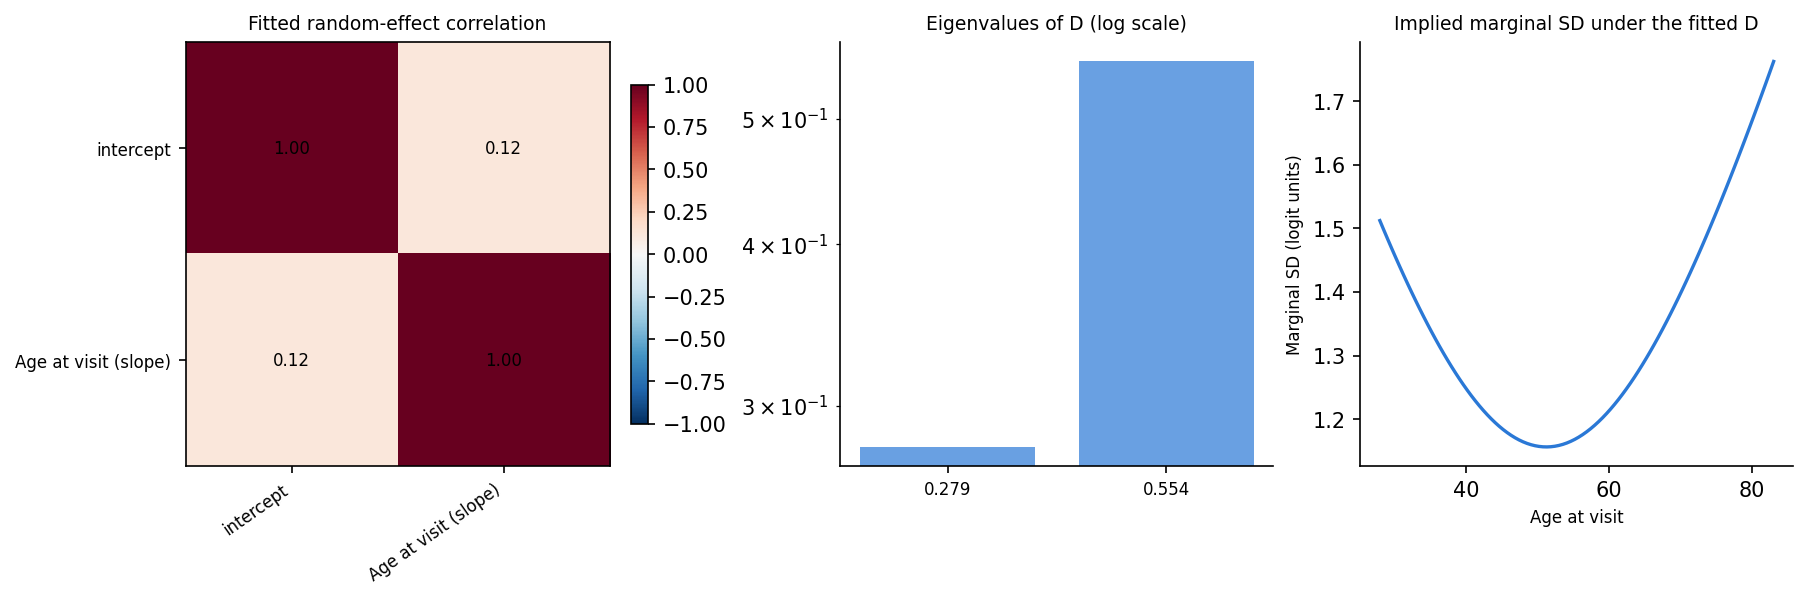

In [11]:
## random-effect covariance D (3/3): correlation heatmap, eigenvalues, and the marginal SD of the outcome implied by D
n_panels = 3 if q_re > 1 else 2
fig, axs = plt.subplots(1, n_panels, figsize=(12, 3.8), layout="constrained", dpi=150)

ax = axs[0]                                                                    # correlation heatmap
im = ax.imshow(corr_re, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(q_re)); ax.set_xticklabels(re_names, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(q_re)); ax.set_yticklabels(re_names, fontsize=8)
for i in range(q_re):
    for j in range(q_re):
        ax.text(j, i, f"{corr_re[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Fitted random-effect correlation", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8)

ax = axs[1]                                                                    # eigenvalues
ax.bar(range(q_re), ev, color=blue, alpha=0.7)
ax.set_yscale("log")
ax.set_xticks(range(q_re)); ax.set_xticklabels([f"{e:.3g}" for e in ev], fontsize=8)
ax.set_title("Eigenvalues of D (log scale)", fontsize=9)

if q_re > 1:                                                                   # marginal SD as the first random-slope covariate moves, the others at their mean
    ax, c = axs[2], random_slope_cols[0]
    z_grid = np.linspace(re_z[c].quantile(.01), re_z[c].quantile(.99), 100)
    w = np.zeros((len(z_grid), q_re))
    w[:, 0], w[:, 1] = 1.0, z_grid                                             # design row (1, z) for the intercept and that slope
    marginal_sd = np.sqrt(np.einsum("ni,ij,nj->n", w, D, w) + s2)
    ax.plot(z_grid * sd[c] + mu[c], marginal_sd, color=blue, lw=1.6)
    ax.set_xlabel(dict((cc[0], cc[1]) for cc in cont_spec)[c], fontsize=8)
    ax.set_ylabel(f"Marginal SD ({re_unit})", fontsize=8)
    ax.set_title("Implied marginal SD under the fitted D", fontsize=9)

for a in axs[1:]:
    a.spines[["top", "right"]].set_visible(False)
plt.show()

residual SD 0.86; skewness 0.03; excess kurtosis 3.87


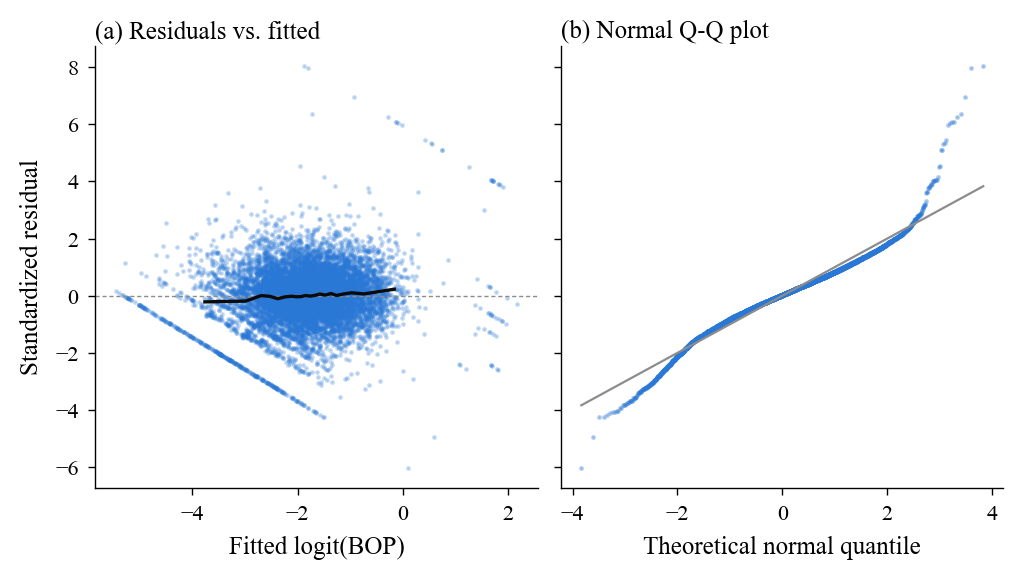

R-squared on the model scale (logit(bleeding)):
marginal R2 (fixed + smooths)           0.037
conditional R2 (+ random effects)       0.528
share of variance: fixed + smooths      0.037
share of variance: random effects       0.491
share of variance: residual             0.472
squared correlation, marginal fit       0.040
squared correlation, conditional fit    0.527
squared correlation on the percentage scale: marginal 0.040, conditional 0.496


In [12]:
## residual diagnostics: conditional residuals vs fitted values and normality
fit_c = ss.fitted_values(conditional=True); res = ss.residuals(conditional=True)
res_s = res / np.sqrt(s2)
with plt.rc_context(ieee):                                    # same IEEE settings as the fitted-curve figure (results-figures cell)
    fig, axs = plt.subplots(1, 2, figsize=(5.0, 3.0), sharey=True, layout="constrained", dpi=200)
    q_bins = pd.qcut(fit_c, 20, duplicates="drop")
    ax = axs[0]
    ax.plot(fit_c, res_s, ".", color=blue, ms=1.5, alpha=0.25, rasterized=True)   # points rasterized so a vector PDF stays small
    ax.axhline(0, color="0.55", lw=0.5, ls=(0, (3, 2)))
    ax.plot(pd.Series(fit_c).groupby(q_bins, observed=True).mean(), pd.Series(res_s).groupby(q_bins, observed=True).mean(), color=ink, lw=1.2)   # binned mean (20 bins)
    ax.set_xlabel({"logit": "Fitted logit(BOP)", "log1p": "Fitted log(BOP% + 1)", "none": "Fitted BOP%"}[outcome_transform]); ax.set_ylabel("Standardized residual")
    ax.set_title("(a) Residuals vs. fitted", loc="left", pad=3)
    ax = axs[1]
    st = stats.probplot(res_s, dist="norm")
    ax.plot(st[0][0], st[0][1], ".", color=blue, ms=1.5, alpha=0.35, rasterized=True)
    ax.plot(st[0][0], st[0][0], color="0.55", lw=0.8)
    ax.set_xlabel("Theoretical normal quantile")
    ax.set_title("(b) Normal Q-Q plot", loc="left", pad=3)
    for a_ in axs:
        a_.spines[["top", "right"]].set_visible(False); a_.minorticks_off(); a_.set_box_aspect(1)   # square panels
    print(f"residual SD {res.std():.2f}; skewness {stats.skew(res):.2f}; excess kurtosis {stats.kurtosis(res):.2f}")
    plt.show()

## R-squared (Nakagawa-Schielzeth variance decomposition, model scale): marginal = fixed part and smooths, conditional = fixed part, smooths and random effects
D_ = ss.D.cpu().numpy(); s2_ = float(ss.sigma2)
y_mod = y.numpy().ravel()
fit_m = ss.fitted_values(conditional=False)                   # X beta + smooths (marginal)
var_f = fit_m.var()
var_re = np.einsum("ni,ij,nj->n", Z, D_, Z).mean()            # average variance contributed by the random intercept and slopes over the observations
var_tot = var_f + var_re + s2_
r2 = pd.Series({"marginal R2 (fixed + smooths)": var_f / var_tot,
                "conditional R2 (+ random effects)": (var_f + var_re) / var_tot,
                "share of variance: fixed + smooths": var_f / var_tot,
                "share of variance: random effects": var_re / var_tot,
                "share of variance: residual": s2_ / var_tot,
                "squared correlation, marginal fit": np.corrcoef(y_mod, fit_m)[0, 1] ** 2,
                "squared correlation, conditional fit": np.corrcoef(y_mod, fit_c)[0, 1] ** 2})
print(f"R-squared on the model scale ({ {'logit': 'logit(bleeding)', 'log1p': 'log(bleeding + 1)', 'none': 'percentage'}[outcome_transform] }):")
print(r2.round(3).to_string())
if outcome_transform != "none":                               # back on the percentage scale: squared correlation with the raw percentage (not a variance decomposition)
    back = (lambda v: 101 / (1 + np.exp(-v)) - 0.5) if outcome_transform == "logit" else np.expm1
    print(f"squared correlation on the percentage scale: marginal {np.corrcoef(y_raw, back(fit_m))[0, 1] ** 2:.3f}, conditional {np.corrcoef(y_raw, back(fit_c))[0, 1] ** 2:.3f}")


In [13]:
## LaTeX table: fixed effects (continuous terms in natural units, log(BOP% + 1) scale) and variance components, printed (no file is written)
tex_labels = {"baseline_diagnosis: 2 vs. 1": "Severity class 2 (vs.\\ class 1)", "baseline_diagnosis: 3 vs. 1": "Severity class 3 (vs.\\ class 1)",
              "sex: female": "Female (vs.\\ male)", "ever_smoker: ever": "Ever-smoker (vs.\\ never-smoker)",
              "class 2 x sex: female": "Class 2 $\\times$ female", "class 3 x sex: female": "Class 3 $\\times$ female"}
tex_labels |= {x_names[k]: f"{lab} ({unit})" for k, (c, lab, size, unit) in enumerate(cont_spec)}
tex_labels = {k: v.replace("%", "\\%").replace(">=", "$\\geq$") for k, v in tex_labels.items()}
num = lambda v, d=3: f"${v:.{d}f}$"                                      # math mode for proper minus signs
pfmt_tex = lambda p: "$<$0.001" if p < 1e-3 else f"{p:.3f}"
rows_tex = []
for k, term in enumerate(x_names):
    e, lo, hi = fx.loc[term, ["estimate", "ci_lower", "ci_upper"]].astype(float)
    if k < len(cont_spec):                                              # continuous: per SD -> per natural unit of cont_spec
        c, _, size, _ = cont_spec[k]; e, lo, hi = (v / sd[c] * size for v in (e, lo, hi))
    rows_tex.append(f"\\hspace{{1em}}{tex_labels[term]} & {num(e)} ({num(lo)}, {num(hi)}) & "
                    f"{pfmt_tex(fx.loc[term, 'p_value'])} & {pfmt_tex(fx.loc[term, 'q_value'])} \\\\")
D_ = ss.D.detach().cpu().numpy() if hasattr(ss.D, "detach") else np.asarray(ss.D)
sd_re_ = np.sqrt(np.diag(D_)); corr_ = D_ / np.outer(sd_re_, sd_re_)
unit_of = {c: (size, unit) for c, _, size, unit in cont_spec}
to_nat = [1.0] + [unit_of[c][0] / sd[c] for c in random_slope_cols]       # slope SDs per SD of the covariate -> per natural unit
re_tex = ["Intercept"] + [f"{re_label[c][:1].lower() + re_label[c][1:]} ({unit_of[c][1]})" for c in random_slope_cols]
re_tex = [r.replace("%", "\\%") for r in re_tex]
var_rows = [f"\\hspace{{1em}}SD, {'random intercept' if i == 0 else 'random slope, ' + re_tex[i]} & {num(sd_re_[i] * to_nat[i])} & & \\\\" for i in range(len(re_tex))]
var_rows += [f"\\hspace{{1em}}Correlation, {re_tex[i].split(' (')[0].lower() if i else 'intercept'} and {re_tex[j].split(' (')[0].lower()} & {num(corr_[i, j], 2)} & & \\\\"
             for i in range(len(re_tex)) for j in range(i + 1, len(re_tex))]
var_rows += [f"\\hspace{{1em}}Residual SD & {num(np.sqrt(float(ss.sigma2)))} & & \\\\"]
if corr_structure != "iid":
    var_rows += [f"\\hspace{{1em}}Residual correlation ({'compound symmetry' if corr_structure == 'cs' else 'AR(1)'}) & {num(float(ss.rho), 2)} & & \\\\"]
tex = "\n".join([r"\begin{tabular}{lccc}", r"\toprule",
                 r"Term & Estimate (95\% CI) & $p$ & $q$ \\", r"\midrule",
                 r"\multicolumn{4}{l}{\textit{Fixed effects, $\log(\mathrm{BOP\%} + 1)$ scale}} \\"] + rows_tex
                + [r"\addlinespace", r"\multicolumn{4}{l}{\textit{Variance components}} \\"] + var_rows + [r"\bottomrule", r"\end{tabular}"])
print(tex)

\begin{tabular}{lccc}
\toprule
Term & Estimate (95\% CI) & $p$ & $q$ \\
\midrule
\multicolumn{4}{l}{\textit{Fixed effects, $\log(\mathrm{BOP\%} + 1)$ scale}} \\
\hspace{1em}Age at visit (per year) & $-0.004$ ($-0.010$, $0.002$) & 0.228 & 0.380 \\
\hspace{1em}Calendar year of visit (per year) & $0.013$ ($0.003$, $0.022$) & 0.012 & 0.030 \\
\hspace{1em}Teeth at visit (per tooth) & $-0.008$ ($-0.023$, $0.007$) & 0.293 & 0.419 \\
\hspace{1em}log(time since preceding visit, days) (per unit) & $0.274$ ($0.232$, $0.315$) & $<$0.001 & $<$0.001 \\
\hspace{1em}Severity class 2 (vs.\ class 1) & $0.486$ ($0.183$, $0.790$) & 0.002 & 0.006 \\
\hspace{1em}Severity class 3 (vs.\ class 1) & $0.620$ ($0.301$, $0.940$) & $<$0.001 & $<$0.001 \\
\hspace{1em}Female (vs.\ male) & $-0.120$ ($-0.476$, $0.236$) & 0.509 & 0.637 \\
\hspace{1em}Ever-smoker (vs.\ never-smoker) & $-0.100$ ($-0.229$, $0.029$) & 0.128 & 0.256 \\
\hspace{1em}Class 2 $\times$ female & $0.060$ ($-0.337$, $0.456$) & 0.768 & 0.854 \\
\hspa